# Pipeline de datos: Web Scraping + API con Pokémon

**Objetivo de la clase:** construir, paso a paso, un dataset limpio de Pokémon combinando **dos fuentes distintas**, y aprender en el camino los problemas reales que aparecen cuando se unen datos de orígenes diferentes.

| Fuente | Técnica | Qué nos da |
|---|---|---|
| [pokemondb.net/pokedex/all](https://pokemondb.net/pokedex/all) | Web scraping (`requests` + `BeautifulSoup`) | ID, nombre, forma, tipos y estadísticas base |
| [pokeapi.co](https://pokeapi.co/) | API REST (JSON) | peso, altura, experiencia base y habilidades |

## Qué vas a aprender
1. Qué es **web scraping** y cómo leer una tabla HTML.
2. Cómo consumir una **API REST** con reintentos, *backoff* exponencial y caché en disco.
3. Qué es el **grano** de una tabla (¿qué representa una fila?) y por qué importa.
4. Cómo **unir** dos datasets con una **llave estable** y comprobar que el join es el esperado.
5. Cómo **limpiar, tipar y validar** un dataset con `pandas`.
6. Buenas prácticas: funciones pequeñas, constantes de configuración, `logging`, manejo de excepciones.

## El flujo completo (ETL)

```
 pokemondb.net ─scraping─▶ df_scrape ─▶ df_base ─┐
                                                  ├─ merge por id ─▶ df_final ─ limpieza + validación ─▶ CSV
 pokeapi.co    ─────API───▶ df_api ──────────────┘
   (Extract)                    (Transform)                                        (Load)
```

> **Requisitos:** `pip install -r requirements.txt` (o `pip install requests beautifulsoup4 pandas matplotlib`)
>
> **Tip para la clase:** en la primera celda de código puedes poner `MAX_POKEMON = 25` para una demo de ~10 segundos. Con `None` se procesan los 1025 Pokémon (~5 minutos la primera vez; las siguientes son instantáneas gracias a la caché).

## Paso 0 · Configuración y verificación del entorno

**Idea clave:** un pipeline reproducible empieza por *declarar su configuración en un solo lugar* y comprobar que las dependencias existen antes de hacer trabajo costoso.

- Las **constantes en MAYÚSCULAS** (URLs, rutas, límites) van arriba: si algo cambia, se modifica en un solo sitio.
- Usamos `logging` en lugar de `print`: tiene niveles (`INFO`, `WARNING`, `ERROR`) y marca de tiempo, indispensable para depurar pipelines que corren sin supervisión.
- `MAX_POKEMON` permite hacer pruebas rápidas sin descargar todo.

In [1]:
import json
import logging
import time
from pathlib import Path
from typing import Dict, Optional

try:
    import requests
    import pandas as pd
    from bs4 import BeautifulSoup
except ImportError as e:
    raise SystemExit(f"Falta una dependencia: {e}. Instala con: pip install -r requirements.txt")

# --- Configuración ---------------------------------------------------------
URL_POKEMONDB = "https://pokemondb.net/pokedex/all"
URL_POKEAPI = "https://pokeapi.co/api/v2/pokemon/{id}"   # se rellena con el ID del Pokémon

MAX_POKEMON = None                         # None = todos. Usa 25 para una demo rápida.
PAUSA_ENTRE_PETICIONES = 0.1               # segundos; cortesía con el servidor
CACHE_PATH = Path(".cache/pokeapi_cache.json")
OUTPUT_PATH = Path("data/pokemon_dataset.csv")

HEADERS = {"User-Agent": "Mozilla/5.0 (clase-ingenieria-de-datos; uso educativo)"}
STAT_COLUMNS = ["total", "hp", "attack", "defense", "sp_atk", "sp_def", "speed"]

logging.basicConfig(level=logging.INFO, format="%(asctime)s - %(levelname)s - %(message)s")
logging.getLogger("matplotlib").setLevel(logging.WARNING)   # silencia mensajes internos de matplotlib
logger = logging.getLogger("pokemon_pipeline")
logger.info("Iniciando el pipeline de datos de Pokémon")

2026-11-18 17:19:45,804 - INFO - Iniciando el pipeline de datos de Pokémon


## Paso 1 · Extract: Web Scraping de Pokémon Database

**Idea clave:** cuando un sitio no ofrece API, podemos leer su HTML. El scraping tiene tres fases:

1. **Descargar** la página: `requests.get(url)`.
2. **Parsear** el HTML: `BeautifulSoup(html, 'html.parser')`.
3. **Navegar** hasta la tabla (`<table id="pokedex">`) y recorrer cada fila `<tr>` leyendo sus celdas `<td>`.

Detalles que vale la pena notar:
- Enviamos un `User-Agent`; muchos sitios rechazan el de `requests` por defecto.
- `timeout=10` evita que el programa se cuelgue para siempre.
- `raise_for_status()` convierte un error HTTP (404, 500...) en una excepción.
- Saltamos las filas incompletas en lugar de romper todo el proceso.
- Las 7 estadísticas se leen con un `zip` en vez de repetir 7 líneas casi idénticas (principio **DRY**).
- En esta etapa guardamos **todo como texto**, tal cual viene de la web ("extraer sin transformar"). El tipado va después.

> **Mira la columna `form`:** `Venusaur` aparece dos veces con el mismo `id`. La segunda fila es su *Mega Evolución*. La página lista cada **forma alternativa** como una fila aparte, así que la tabla tiene más filas que Pokémon distintos.

In [2]:
def scrape_pokemondb(url: str) -> pd.DataFrame:
    """Descarga la Pokédex de pokemondb.net y devuelve un DataFrame (todo como texto).

    Cada fila del HTML es una *forma* de un Pokémon (base, Mega, regional, etc.).
    """
    logger.info(f"Realizando solicitud HTTP a {url}")
    response = requests.get(url, headers=HEADERS, timeout=10)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    table = soup.find("table", {"id": "pokedex"})
    if table is None:
        raise ValueError("No se encontró la tabla con id='pokedex' (¿cambió la página?)")

    records = []
    for row in table.find_all("tr")[1:]:            # [1:] salta el encabezado
        cols = row.find_all("td")
        if len(cols) < 10:
            logger.warning("Fila incompleta, se omite")
            continue

        name_cell = cols[1]
        small = name_cell.find("small")             # aquí viene el nombre de la forma ("Mega Venusaur")
        record = {
            "id": cols[0].text.strip(),
            "name": name_cell.find("a", class_="ent-name").text.strip(),
            "form": small.text.strip() if small else None,
            "types": [a.text.strip() for a in cols[2].find_all("a")],
        }
        # cols[3:10] son: total, hp, attack, defense, sp_atk, sp_def, speed
        record.update({stat: cell.text.strip() for stat, cell in zip(STAT_COLUMNS, cols[3:10])})
        records.append(record)

    df = pd.DataFrame(records)
    logger.info(f"Scraping completado: {len(df)} filas (formas incluidas)")
    return df


df_scrape = scrape_pokemondb(URL_POKEMONDB)
df_scrape.head()

2026-11-18 17:19:45,810 - INFO - Realizando solicitud HTTP a https://pokemondb.net/pokedex/all


2026-11-18 17:19:46,882 - INFO - Scraping completado: 1261 filas (formas incluidas)


,id,name,form,types,total,hp,attack,defense,sp_atk,sp_def,speed
0,0001,Bulbasaur,NaN,"[Grass, Poison]",318,45,49,49,65,65,45
1,0002,Ivysaur,NaN,"[Grass, Poison]",405,60,62,63,80,80,60
2,0003,Venusaur,NaN,"[Grass, Poison]",525,80,82,83,100,100,80
3,0003,Venusaur,Mega Venusaur,"[Grass, Poison]",625,80,100,123,122,120,80
4,0004,Charmander,NaN,[Fire],309,39,52,43,60,50,65


### Mini-ejercicio: ¿qué son las filas repetidas?
Antes de seguir, miremos qué pasa con un mismo `id`. Esto es **explorar los datos antes de transformarlos**, un hábito fundamental.

In [3]:
# Todas las formas del Pokémon #0006 (Charizard) y del #0003 (Venusaur)
df_scrape[df_scrape["id"].isin(["0003", "0006"])][["id", "name", "form", "types", "total"]]

,id,name,form,types,total
2,0003,Venusaur,NaN,"[Grass, Poison]",525
3,0003,Venusaur,Mega Venusaur,"[Grass, Poison]",625
6,0006,Charizard,NaN,"[Fire, Flying]",534
7,0006,Charizard,Mega Charizard X,"[Fire, Dragon]",634
8,0006,Charizard,Mega Charizard Y,"[Fire, Flying]",634


## Paso 2 · Transform: tipar y decidir el *grano* de la tabla

### Grano
El **grano** (*granularity*) responde: *"¿qué representa exactamente una fila?"* Ahora mismo una fila es una **forma**; nosotros queremos que sea **un Pokémon**. Para lograrlo nos quedamos con la **forma base**: la primera fila de cada `id`.

> En el notebook original esto ocurría de forma **silenciosa** dentro del `merge` (se perdían unas 200 filas sin avisar). Aquí lo hacemos **explícito y con un log**: una buena práctica es que *nunca* se pierdan datos sin dejar rastro.

### Tipado
Los datos llegaron como texto. Convertimos con `pd.to_numeric(..., errors='coerce')`: lo que no se pueda convertir pasa a `NaN` en lugar de lanzar un error. Usamos el tipo `Int64` (con mayúscula), el entero de pandas que **admite nulos**.

In [4]:
def cast_numeric_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Convierte id y estadísticas de texto a enteros (con soporte de nulos)."""
    df = df.copy()
    for col in ["id"] + STAT_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce").astype("Int64")
    return df


def select_base_forms(df: pd.DataFrame) -> pd.DataFrame:
    """Deja una sola fila por Pokémon: su forma base (la primera aparición del id)."""
    before = len(df)
    df_base = df.drop_duplicates(subset="id", keep="first").reset_index(drop=True)
    logger.info(f"Formas alternativas descartadas: {before - len(df_base)} (de {before} filas quedan {len(df_base)})")
    return df_base


df_base = select_base_forms(cast_numeric_columns(df_scrape))
if MAX_POKEMON:
    df_base = df_base.head(MAX_POKEMON)
    logger.info(f"MAX_POKEMON={MAX_POKEMON}: se procesarán solo los primeros {len(df_base)}")

df_base.dtypes

2026-11-18 17:19:46,904 - INFO - Formas alternativas descartadas: 236 (de 1261 filas quedan 1025)


id          Int64
name          str
form          str
types      object
total       Int64
hp          Int64
attack      Int64
defense     Int64
sp_atk      Int64
sp_def      Int64
speed       Int64
dtype: object

## Paso 3 · Extract: Consumir la PokeAPI

**Idea clave:** una API REST devuelve datos estructurados (JSON) a partir de una URL, por ejemplo <https://pokeapi.co/api/v2/pokemon/1> (Bulbasaur).

### Llave estable: ID, no nombre
La versión anterior pedía los datos **por nombre**, y fallaba con `Farfetch'd`, `Mr. Mime`, `Nidoran♀`... porque la API los escribe distinto (`farfetchd`, `mr-mime`, `nidoran-f`). Los **nombres son frágiles**; el **ID numérico** es estable. Si ambas fuentes comparten ID, ¡úsalo!

### Una llamada real puede fallar de muchas formas
La función `fetch_pokemon_data` es **defensiva**:

| Situación | Qué hacemos |
|---|---|
| `200 OK` | Extraemos los campos del JSON |
| `404 Not Found` | `WARNING` y devolvemos `None` (reintentar no sirve) |
| `429 Too Many Requests` | Esperamos y reintentamos |
| Error de red / `5xx` | Esperamos y reintentamos hasta `max_retries` |

La espera crece de forma **exponencial** (1 s, 2 s, 4 s...). Se llama *exponential backoff* y es el estándar para no saturar a un servidor que ya está sufriendo.

### Mejoras de eficiencia
- `requests.Session()` reutiliza la conexión TCP: es bastante más rápido que abrir una nueva por petición.
- **Caché en disco** (`.cache/pokeapi_cache.json`): si el proceso se interrumpe o lo repites, no vuelve a pedir lo que ya tiene.
- Pedimos **una vez por Pokémon** (antes se pedían 1215 veces, incluso para formas repetidas).

### Unidades
La API entrega la altura en **decímetros** y el peso en **hectogramos**. Convertimos a **metros** y **kilogramos** (÷ 10). Poner la unidad en el nombre de la columna (`height_m`, `weight_kg`) evita confusiones.

In [5]:
def fetch_pokemon_data(pokemon_id: int, session: requests.Session,
                       max_retries: int = 3, backoff: float = 1.0) -> Optional[Dict]:
    """Pide un Pokémon a la PokeAPI por ID. Devuelve un dict, o None si no se pudo."""
    url = URL_POKEAPI.format(id=pokemon_id)

    for attempt in range(1, max_retries + 1):
        wait = backoff * 2 ** (attempt - 1)          # 1 s, 2 s, 4 s...
        try:
            response = session.get(url, timeout=10)

            if response.status_code == 404:
                logger.warning(f"ID {pokemon_id} no existe en la API (404)")
                return None
            if response.status_code == 429:
                logger.warning(f"Límite de tasa (429). Esperando {wait:.0f} s")
                time.sleep(wait)
                continue

            response.raise_for_status()
            data = response.json()
            return {
                "id": pokemon_id,
                "height_m": data["height"] / 10,        # decímetros -> metros
                "weight_kg": data["weight"] / 10,       # hectogramos -> kilogramos
                "base_experience": data["base_experience"],
                "abilities": [a["ability"]["name"] for a in data["abilities"]],
            }
        except requests.exceptions.RequestException as e:
            logger.warning(f"ID {pokemon_id}, intento {attempt}/{max_retries}: {e}")
            time.sleep(wait)

    logger.error(f"ID {pokemon_id}: sin datos tras {max_retries} intentos")
    return None


def load_cache() -> Dict[str, Dict]:
    return json.loads(CACHE_PATH.read_text()) if CACHE_PATH.exists() else {}


def save_cache(cache: Dict[str, Dict]) -> None:
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    CACHE_PATH.write_text(json.dumps(cache))


def fetch_all_pokemon(ids) -> pd.DataFrame:
    """Descarga (o lee de la caché) los datos de todos los IDs dados."""
    cache = load_cache()
    pending = [i for i in ids if str(i) not in cache]
    logger.info(f"{len(ids) - len(pending)} en caché, {len(pending)} por descargar")

    with requests.Session() as session:
        session.headers.update(HEADERS)
        for n, pokemon_id in enumerate(pending, start=1):
            record = fetch_pokemon_data(pokemon_id, session)
            if record:
                cache[str(pokemon_id)] = record
            time.sleep(PAUSA_ENTRE_PETICIONES)
            if n % 100 == 0:
                save_cache(cache)                    # guardado parcial por si se interrumpe
                logger.info(f"  progreso: {n}/{len(pending)}")
    save_cache(cache)

    return pd.DataFrame([cache[str(i)] for i in ids if str(i) in cache])


df_api = fetch_all_pokemon([int(i) for i in df_base["id"]])
logger.info(f"Datos de la API obtenidos para {len(df_api)} Pokémon")
df_api.head()

2026-11-18 17:19:46,911 - INFO - 0 en caché, 1025 por descargar


2026-11-18 17:20:01,139 - INFO -   progreso: 100/1025


2026-11-18 17:20:16,983 - INFO -   progreso: 200/1025


2026-11-18 17:20:34,653 - INFO -   progreso: 300/1025


2026-11-18 17:20:52,405 - INFO -   progreso: 400/1025


2026-11-18 17:21:15,126 - INFO -   progreso: 500/1025


... (3 outputs left out)

2026-11-18 17:22:38,832 - INFO -   progreso: 900/1025


2026-11-18 17:23:00,807 - INFO -   progreso: 1000/1025


2026-11-18 17:23:06,424 - INFO - Datos de la API obtenidos para 1025 Pokémon


,id,height_m,weight_kg,base_experience,abilities
0,1,0.7,6.9,64,"[overgrow, chlorophyll]"
1,2,1.0,13.0,142,"[overgrow, chlorophyll]"
2,3,2.0,100.0,236,"[overgrow, chlorophyll]"
3,4,0.6,8.5,62,"[blaze, solar-power]"
4,5,1.1,19.0,142,"[blaze, solar-power]"


## Paso 4 · Transform: Combinar los datasets (merge)

**Idea clave:** un *join* une dos tablas usando una columna llave. Ahora la llave es `id`.

Usamos `how='left'`: se conservan **todas** las filas del scraping y se agregan las columnas de la API cuando hay coincidencia.

Dos herramientas de `pandas` para **no confiar a ciegas** en un join:
- `validate="one_to_one"`: pandas lanza un error si algún `id` aparece más de una vez en alguno de los lados. Si el grano estuviera mal (como antes), nos enteraríamos al instante.
- `indicator=True`: agrega la columna `_merge` que indica de dónde vino cada fila (`both`, `left_only`, `right_only`). Así contamos cuántas filas **no** encontraron pareja.

In [6]:
def merge_datasets(df_scrape: pd.DataFrame, df_api: pd.DataFrame) -> pd.DataFrame:
    """Une scraping y API por id, verificando que el join sea 1 a 1."""
    df_api = df_api.copy()
    df_api["id"] = df_api["id"].astype("Int64")

    merged = pd.merge(df_scrape, df_api, on="id", how="left",
                      validate="one_to_one", indicator=True)

    resumen = merged["_merge"].value_counts()
    logger.info(f"Filas con pareja en la API: {resumen.get('both', 0)} | sin pareja: {resumen.get('left_only', 0)}")
    return merged.drop(columns="_merge")


df_final = merge_datasets(df_base, df_api)
df_final.head()

2026-11-18 17:23:06,435 - INFO - Filas con pareja en la API: 1025 | sin pareja: 0


,id,name,form,types,total,hp,attack,defense,sp_atk,sp_def,speed,height_m,weight_kg,base_experience,abilities
0,1,Bulbasaur,NaN,"[Grass, Poison]",318,45,49,49,65,65,45,0.7,6.9,64,"[overgrow, chlorophyll]"
1,2,Ivysaur,NaN,"[Grass, Poison]",405,60,62,63,80,80,60,1.0,13.0,142,"[overgrow, chlorophyll]"
2,3,Venusaur,NaN,"[Grass, Poison]",525,80,82,83,100,100,80,2.0,100.0,236,"[overgrow, chlorophyll]"
3,4,Charmander,NaN,[Fire],309,39,52,43,60,50,65,0.6,8.5,62,"[blaze, solar-power]"
4,5,Charmeleon,NaN,[Fire],405,58,64,58,80,65,80,1.1,19.0,142,"[blaze, solar-power]"


## Paso 5 · Transform: Limpieza y validación

### Limpieza
- Garantizamos que `types` y `abilities` sean listas (nunca `NaN`).
- **No rellenamos con `0`** los pesos o alturas que falten. Un peso de `0` es un dato *falso*; es distinto de *"no lo sé"*. Dejamos `NaN` y así los promedios y gráficos no se contaminan.
- Eliminamos filas sin `id` o sin `name`.

### Validación (*data quality checks*)
Limpiar no basta: hay que **demostrar** que el resultado es correcto. Escribimos reglas que deben cumplirse y el pipeline **falla de forma ruidosa** si alguna no se cumple. Algunas de las reglas:
- El `id` es único (el grano es correcto).
- `total` debe ser **igual a la suma** de las seis estadísticas (una regla de negocio que verifica que el scraping leyó bien las columnas).
- Peso y altura son positivos.
- Todo Pokémon tiene al menos un tipo.

In [7]:
def clean_dataset(df: pd.DataFrame) -> pd.DataFrame:
    """Limpia el dataset combinado y ordena las columnas."""
    df = df.copy()
    df["types"] = df["types"].apply(lambda x: x if isinstance(x, list) else [])
    df["abilities"] = df["abilities"].apply(lambda x: x if isinstance(x, list) else [])
    df["base_experience"] = pd.to_numeric(df["base_experience"], errors="coerce").astype("Int64")
    df = df.dropna(subset=["id", "name"])

    columns = ["id", "name", "types"] + STAT_COLUMNS + ["height_m", "weight_kg", "base_experience", "abilities"]
    df = df[columns].reset_index(drop=True)
    logger.info(f"Limpieza completada: {len(df)} filas")
    return df


def validate_dataset(df: pd.DataFrame) -> None:
    """Lanza AssertionError si el dataset incumple alguna regla de calidad."""
    stats_sin_total = [c for c in STAT_COLUMNS if c != "total"]
    checks = {
        "id único": df["id"].is_unique,
        "sin nulos en id, name y estadísticas": not df[["id", "name"] + STAT_COLUMNS].isna().any().any(),
        "total = suma de las 6 estadísticas": bool((df[stats_sin_total].sum(axis=1) == df["total"]).all()),
        "altura y peso positivos (donde existen)": bool((df[["height_m", "weight_kg"]].dropna() > 0).all().all()),
        "al menos un tipo por Pokémon": bool((df["types"].str.len() >= 1).all()),
    }
    for name, ok in checks.items():
        logger.info(f"  [{'OK' if ok else 'FALLA'}] {name}")
    failed = [name for name, ok in checks.items() if not ok]
    assert not failed, f"Reglas de calidad incumplidas: {failed}"


df_clean = clean_dataset(df_final)
validate_dataset(df_clean)
df_clean.head()

2026-11-18 17:23:06,445 - INFO - Limpieza completada: 1025 filas


2026-11-18 17:23:06,448 - INFO -   [OK] id único


2026-11-18 17:23:06,448 - INFO -   [OK] sin nulos en id, name y estadísticas


2026-11-18 17:23:06,448 - INFO -   [OK] total = suma de las 6 estadísticas


2026-11-18 17:23:06,448 - INFO -   [OK] altura y peso positivos (donde existen)


2026-11-18 17:23:06,449 - INFO -   [OK] al menos un tipo por Pokémon


,id,name,types,total,hp,attack,defense,sp_atk,sp_def,speed,height_m,weight_kg,base_experience,abilities
0,1,Bulbasaur,"[Grass, Poison]",318,45,49,49,65,65,45,0.7,6.9,64,"[overgrow, chlorophyll]"
1,2,Ivysaur,"[Grass, Poison]",405,60,62,63,80,80,60,1.0,13.0,142,"[overgrow, chlorophyll]"
2,3,Venusaur,"[Grass, Poison]",525,80,82,83,100,100,80,2.0,100.0,236,"[overgrow, chlorophyll]"
3,4,Charmander,[Fire],309,39,52,43,60,50,65,0.6,8.5,62,"[blaze, solar-power]"
4,5,Charmeleon,[Fire],405,58,64,58,80,65,80,1.1,19.0,142,"[blaze, solar-power]"


## Paso 6 · Load: Guardar el dataset

**Idea clave:** el último paso de un ETL es **persistir** el resultado para reutilizarlo sin repetir todo el proceso.

Decisiones de diseño:
- **Nombre de archivo fijo** (`data/pokemon_dataset.csv`) en vez de un `uuid` aleatorio. Con un nombre aleatorio cada ejecución crea un archivo nuevo y nadie sabe cuál es el "bueno". Si necesitas versionar, usa la fecha o Git.
- Un CSV no tiene listas. Las columnas `types` y `abilities` se guardan separadas por `|` (por ejemplo `Grass|Poison`), un formato fácil de volver a leer con `str.split("|")`.
- `index=False` evita guardar el índice de pandas como columna extra.

In [8]:
def save_dataset(df: pd.DataFrame, path: Path = OUTPUT_PATH) -> None:
    """Guarda el DataFrame en CSV, convirtiendo las listas a texto separado por '|'."""
    path.parent.mkdir(parents=True, exist_ok=True)
    out = df.copy()
    out["types"] = out["types"].str.join("|")
    out["abilities"] = out["abilities"].str.join("|")
    out.to_csv(path, index=False)
    logger.info(f"Dataset guardado en {path} ({len(out)} filas, {out.shape[1]} columnas)")


save_dataset(df_clean)

2026-11-18 17:23:06,461 - INFO - Dataset guardado en data/pokemon_dataset.csv (1025 filas, 14 columnas)


## Paso 7 · Resumen del pipeline

Comparar el número de filas en cada etapa es una forma rápida de detectar pérdidas de datos. Ahora **cada diferencia tiene una explicación** y quedó registrada en el log.

In [9]:
resumen = pd.DataFrame({
    "etapa": ["Scraping (formas incluidas)", "Una fila por Pokémon", "Con datos de la API", "Dataset final"],
    "filas": [len(df_scrape), len(df_base), len(df_api), len(df_clean)],
})
resumen

,etapa,filas
0,Scraping (formas incluidas),1261
1,Una fila por Pokémon,1025
2,Con datos de la API,1025
3,Dataset final,1025


## Paso 8 · ¡Usemos los datos! Análisis rápido

El objetivo de un pipeline es que los datos **sirvan para algo**. Con el dataset limpio ya podemos responder preguntas en pocas líneas.

Fíjate en `explode("types")`: como un Pokémon puede tener 2 tipos, `explode` crea una fila por cada tipo para poder agrupar.

In [10]:
# 1) Los 10 Pokémon con mayor poder total
df_clean.nlargest(10, "total")[["id", "name", "types", "total"]]

,id,name,types,total
492,493,Arceus,[Normal],720
889,890,Eternatus,"[Poison, Dragon]",690
149,150,Mewtwo,[Psychic],680
248,249,Lugia,"[Psychic, Flying]",680
249,250,Ho-oh,"[Fire, Flying]",680
383,384,Rayquaza,"[Dragon, Flying]",680
482,483,Dialga,"[Steel, Dragon]",680
483,484,Palkia,"[Water, Dragon]",680
486,487,Giratina,"[Ghost, Dragon]",680
642,643,Reshiram,"[Dragon, Fire]",680


In [11]:
# 2) Promedio de estadísticas por tipo (un Pokémon de 2 tipos cuenta en ambos)
por_tipo = (
    df_clean.explode("types")
    .groupby("types")[STAT_COLUMNS]
    .mean()
    .round(1)
    .sort_values("total", ascending=False)
)
por_tipo

,total,hp,attack,defense,sp_atk,sp_def,speed
types,,,,,,,
Dragon,504.8,84.1,94.0,83.0,87.2,78.3,78.2
Steel,479.7,71.0,90.7,107.9,71.1,78.9,60.2
Fighting,467.1,77.8,104.3,76.4,63.6,69.7,75.4
Dark,459.6,76.3,93.6,71.4,72.7,68.9,76.8
Psychic,457.5,73.8,67.3,72.6,88.0,84.2,71.6
Ice,453.6,80.1,82.3,75.7,74.9,75.2,65.4
Fire,449.5,69.9,80.6,67.5,86.3,71.0,74.1
Ghost,447.5,65.7,77.4,77.5,81.6,79.1,66.2
Electric,442.2,68.7,74.9,64.9,84.2,67.7,81.9


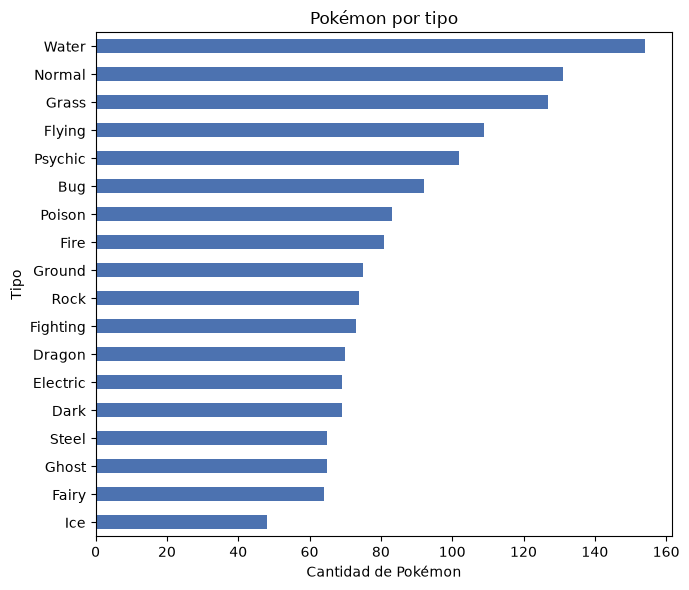

In [12]:
# 3) ¿Cuántos Pokémon hay de cada tipo?
import matplotlib.pyplot as plt

conteo = df_clean.explode("types")["types"].value_counts().sort_values()
ax = conteo.plot(kind="barh", figsize=(7, 6), color="#4c72b0")
ax.set_xlabel("Cantidad de Pokémon")
ax.set_ylabel("Tipo")
ax.set_title("Pokémon por tipo")
plt.tight_layout()
plt.show()

## Para seguir practicando
En el archivo `EJERCICIOS.md` del repositorio hay ejercicios graduados (básico, intermedio, avanzado) para extender este pipeline.

## Resumen de lo aprendido
| Concepto | Dónde lo vimos |
|---|---|
| Web scraping con `requests` + `BeautifulSoup` | Paso 1 |
| Grano de una tabla | Paso 2 |
| Consumo de API, reintentos, *backoff* y caché | Paso 3 |
| Llaves estables y joins validados | Paso 4 |
| Limpieza y validación de calidad | Paso 5 |
| Persistencia de resultados | Paso 6 |